In [5]:
import matplotlib.pyplot as plt
import numpy as np
from deap import tools
from src.objectives import evaluate_objectives

CAPEX_BATTERY = 500.0
BATTERY_LIFETIME = 10.0
OPEX_GRID = 0.30

In [6]:
from src.nsga2 import run_optimization

pareto_front = run_optimization(pop_size=40, n_gen=25, cxpb=0.638, mutpb=0.161)

fits = np.array([ind.fitness.values for ind in pareto_front])
capacities = np.array([ind[0] for ind in pareto_front])

sorted_indices = np.argsort(capacities)
capacities_sorted = capacities[sorted_indices]
fits_sorted = fits[sorted_indices]
costs_nsga = [(CAPEX_BATTERY * f[0] / BATTERY_LIFETIME)+ (OPEX_GRID * f[1])for f in fits_sorted]

print(f"✅ NSGA-II eseguito con successo. Individui nel fronte:"f" {len(capacities)}")

✅ NSGA-II eseguito con successo. Individui nel fronte: 40


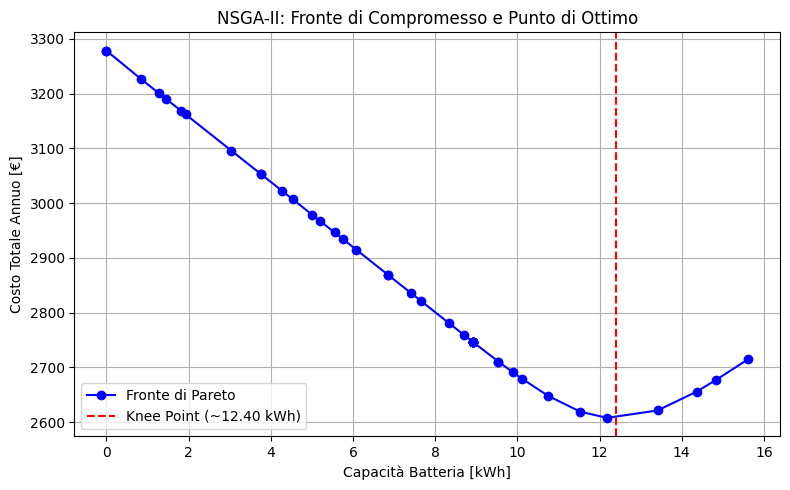

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(capacities_sorted, costs_nsga, 'bo-', label='Fronte di Pareto')
plt.axvline(x=12.40, color='r', linestyle='--', label='Knee Point (~12.40 kWh)')
plt.title('NSGA-II: Fronte di Compromesso e Punto di Ottimo')
plt.xlabel('Capacità Batteria [kWh]')
plt.ylabel('Costo Totale Annuo [€]')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
from src.de import economic_cost_function, result_de

print("--- RISULTATI DIFFERENTIAL EVOLUTION (DE) ---")
print(f"🔹 Capacità Batteria Ottimale: {result_de.x[0]:.4f} kWh")
print(f"🔹 Costo Totale Minimo (J): € {result_de.fun:,.4f} all'anno")
print(f"🔹 Iterazioni eseguite: {result_de.nit}")

Avvio dell'ottimizzazione con Differential Evolution (DE)...

--- RISULTATI DIFFERENTIAL EVOLUTION (DE) ---
Capacità Batteria Ottimale: 12.4008 kWh
Costo Totale Minimo (J): € 2,606.9298
Numero di iterazioni eseguite: 11

📊 CONFRONTO ECONOMICO: BASELINE VS DIFFERENTIAL EVOLUTION
🔸 Scenario Senza Batteria (Baseline): € 3,278.37 /anno
🔹 Scenario Ottimizzato (DE - 12.40 kWh): € 2,606.93 /anno
--------------------------------------------------
💰 Risparmio Economico Netto: € 671.4426 all'anno
📉 Riduzione della spesa energetica: 20.48%
--- RISULTATI DIFFERENTIAL EVOLUTION (DE) ---
🔹 Capacità Batteria Ottimale: 12.4008 kWh
🔹 Costo Totale Minimo (J): € 2,606.9298 all'anno
🔹 Iterazioni eseguite: 11


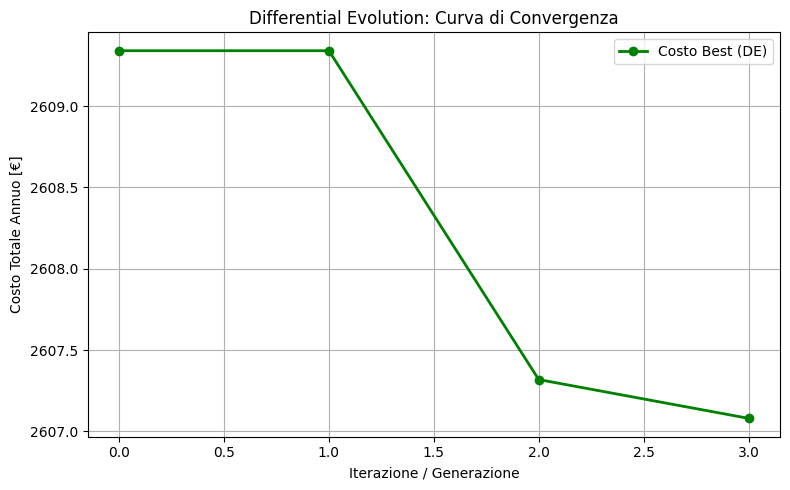

In [ ]:
from scipy.optimize import differential_evolution

de_costs = []


def callback_de(xk, convergence=1.0):
  de_costs.append(economic_cost_function(xk))


differential_evolution(economic_cost_function,bounds=[(0.0, 50.0)],strategy='best1bin',popsize=15,maxiter=20,callback=callback_de,seed=42,)

plt.figure(figsize=(8, 5))
plt.plot(de_costs, 'g-o', linewidth=2, label='Costo Best (DE)')
plt.title('Differential Evolution: Curva di Convergenza')
plt.xlabel('Iterazione / Generazione')
plt.ylabel('Costo Totale Annuo [€]')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
from src.pso import history, pso_cap, pso_cost

print("--- RISULTATI PARTICLE SWARM OPTIMIZATION (PSO) ---")
print(f"🔹 Capacità Batteria Ottimale: {pso_cap:.2f} kWh")
print(f"🔹 Costo Totale Minimo (J): € {pso_cost:,.2f} all'anno")

--- RISULTATI PARTICLE SWARM OPTIMIZATION (PSO) ---
🔹 Capacità Batteria Ottimale: 12.40 kWh
🔹 Costo Totale Minimo (J): € 2,606.93 all'anno


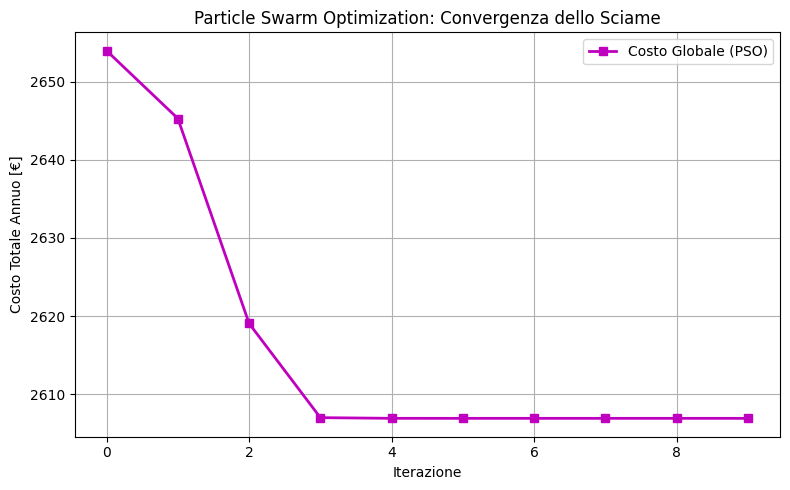

: 

In [ ]:
import matplotlib.pyplot as plt
from src.pso import history

plt.figure(figsize=(8, 5))
plt.plot(history, 'm-s', linewidth=2, label='Costo Globale (PSO)')
plt.title('Particle Swarm Optimization: Convergenza dello Sciame')
plt.xlabel('Iterazione')
plt.ylabel('Costo Totale Annuo [€]')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

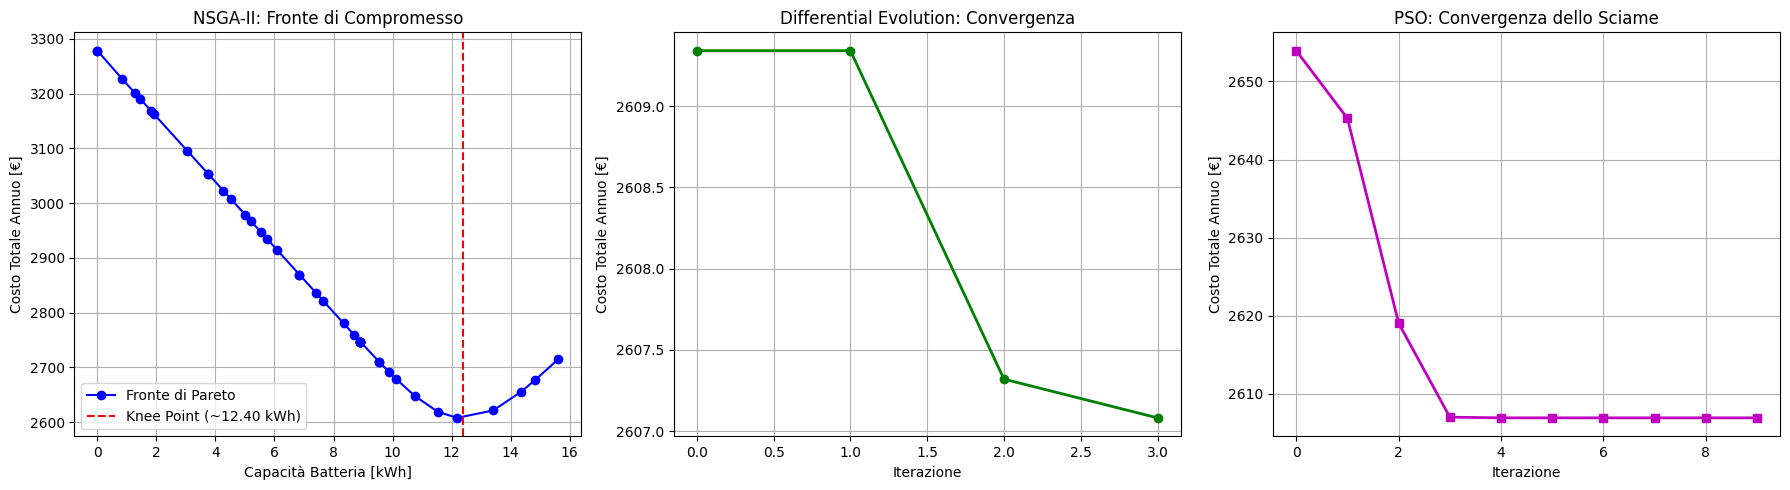

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 5))

# 1. Fronte di Pareto (NSGA-II) con Knee Point evidenziato
plt.subplot(1, 3, 1)
plt.plot(capacities_sorted, costs_nsga, "bo-", label="Fronte di Pareto")
plt.axvline(
    x=12.40, color="r", linestyle="--", label="Knee Point (~12.40 kWh)"
)
plt.title("NSGA-II: Fronte di Compromesso")
plt.xlabel("Capacità Batteria [kWh]")
plt.ylabel("Costo Totale Annuo [€]")
plt.grid(True)
plt.legend()

# 2. Curva di Convergenza Differential Evolution (DE)
de_costs = []


def callback_de(xk, convergence=1.0):
  de_costs.append(economic_cost_function(xk))


from scipy.optimize import differential_evolution

differential_evolution(
    economic_cost_function,
    bounds=[(0.0, 50.0)],
    strategy="best1bin",
    popsize=15,
    maxiter=20,
    callback=callback_de,
    seed=42,
)

plt.subplot(1, 3, 2)
plt.plot(de_costs, "g-o", linewidth=2)
plt.title("Differential Evolution: Convergenza")
plt.xlabel("Iterazione")
plt.ylabel("Costo Totale Annuo [€]")
plt.grid(True)

# 3. Curva di Convergenza PSO (importata direttamente da pso.py)
plt.subplot(1, 3, 3)
plt.plot(history, "m-s", linewidth=2)
plt.title("PSO: Convergenza dello Sciame")
plt.xlabel("Iterazione")
plt.ylabel("Costo Totale Annuo [€]")
plt.grid(True)

plt.tight_layout()
plt.show()